# PYTORCH MASTERY — NOTEBOOK 17 (FINAL)
## Chapters 99–104: Research Paper Implementation → Reimplement Important Models → Code Reading Mastery → Professional PyTorch Code Quality → Master Capstone → Mock AI Engineer Interview

This is the final notebook of the course. It closes with an independent capstone project and a full mock interview.


### PYTORCH MASTERY PROGRESS
Current Chapter: 104 | Current Level: Research Fluency & Mastery Assessment

- [x] Chapters 1–98 *(Notebooks 1–16)*
- [x] Research Paper Implementation
- [x] Reimplement Important Models
- [x] Code Reading Mastery
- [x] Professional PyTorch Code Quality
- [x] **Master Capstone**
- [x] **Mock AI Engineer Interview**

**Full course progress: 104/104 chapters complete.**


---
# CHAPTER 99 — RESEARCH PAPER IMPLEMENTATION

## 1. Concept
Reading and reimplementing a deep learning paper is a genuine, learnable skill — this chapter builds the systematic workflow, then applies it to a real architectural component.

## 2. The Workflow
```
Paper
  ↓
Architecture      -- draw the data flow diagram yourself, don't just read prose
  ↓
Mathematics        -- identify every equation; connect each to a PyTorch operation you already know
  ↓
Dataset             -- what data, what preprocessing, what's genuinely reproducible vs. proprietary
  ↓
Loss                  -- often the most under-specified part of a paper; may require inference/judgment
  ↓
Optimizer               -- hyperparameters are usually in an appendix/table, easy to miss on a first read
  ↓
Training Strategy          -- warmup, schedule, regularization -- genuinely easy to skip, genuinely important
  ↓
Implementation                -- start MINIMAL; get something RUNNING before refining
  ↓
Experiments                     -- reproduce the paper's OWN reported ablations where feasible
  ↓
Reproduction                      -- compare your results against the paper's; investigate GENUINE gaps
```

## 3. Reading a Paper's Architecture Section — a Concrete Exercise


In [ ]:
print("""
Practice excerpt (paraphrased, illustrative, in the style of a typical paper's
architecture description -- NOT quoting any actual paper verbatim):

  'Our module applies a depthwise convolution followed by a pointwise
   convolution, with a residual connection when input and output channel
   counts match. Batch normalization and a ReLU activation follow each
   convolution. The module processes an input of shape (N, C_in, H, W) and
   produces an output of shape (N, C_out, H, W).'

YOUR TASK, before reading the implementation below: sketch this architecture's
data flow and shape transformations YOURSELF, then compare.
""")



Practice excerpt (paraphrased, illustrative, in the style of a typical paper's
architecture description -- NOT quoting any actual paper verbatim):

  'Our module applies a depthwise convolution followed by a pointwise
   convolution, with a residual connection when input and output channel
   counts match. Batch normalization and a ReLU activation follow each
   convolution. The module processes an input of shape (N, C_in, H, W) and
   produces an output of shape (N, C_out, H, W).'

YOUR TASK, before reading the implementation below: sketch this architecture's
data flow and shape transformations YOURSELF, then compare.



In [ ]:
import torch
import torch.nn as nn

class DepthwiseSeparableBlock(nn.Module):
    """A genuine, standard architectural pattern (MobileNet-style, Chapter 39,
    67) reimplemented FOLLOWING the paper-excerpt description above."""

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        # DEPTHWISE: one filter PER input channel -- groups=in_channels is the KEY
        # parameter making this "depthwise" rather than a standard convolution
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=stride,
                                     padding=1, groups=in_channels, bias=False)
        self.bn1 = nn.BatchNorm2d(in_channels)

        # POINTWISE: a standard 1x1 convolution -- mixes information ACROSS channels
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU()
        self.use_residual = (in_channels == out_channels) and (stride == 1)   # per the excerpt's description

    def forward(self, x):
        identity = x

        out = self.relu(self.bn1(self.depthwise(x)))
        out = self.relu(self.bn2(self.pointwise(out)))

        if self.use_residual:
            out = out + identity   # Chapter 39's residual pattern, applied conditionally

        return out


block = DepthwiseSeparableBlock(in_channels=32, out_channels=32, stride=1)
x = torch.randn(4, 32, 16, 16)
output = block(x)
print("Input shape:", x.shape, " Output shape:", output.shape)
print("Residual used (channels match):", block.use_residual)

block2 = DepthwiseSeparableBlock(in_channels=32, out_channels=64, stride=1)
output2 = block2(x)
print("\nChannel-changing block -- Output shape:", output2.shape)
print("Residual used (channels DON'T match):", block2.use_residual)


Input shape: torch.Size([4, 32, 16, 16])  Output shape: torch.Size([4, 32, 16, 16])
Residual used (channels match): True

Channel-changing block -- Output shape: torch.Size([4, 64, 16, 16])
Residual used (channels DON'T match): False


### Why Depthwise-Separable Convolutions Matter — Connecting Math to Motivation
A standard `Conv2d` with `in_channels=C_in, out_channels=C_out, kernel=3` has `C_in × C_out × 3 × 3` parameters. Splitting into depthwise (`C_in × 3 × 3`, via `groups=in_channels`) + pointwise (`C_in × C_out × 1 × 1`) gives roughly `C_in×9 + C_in×C_out` parameters — for typical channel counts, this is a genuinely dramatic reduction (often 8-9x fewer parameters/computation), directly explaining why this pattern underlies MobileNet-family architectures (Chapter 39, 67) specifically designed for edge/mobile deployment.

### Common Mistakes
- Jumping straight to implementation without first sketching the architecture's data flow and shape transformations by hand — skips the understanding step that makes debugging a faithful reimplementation possible at all.
- Missing hyperparameters buried in an appendix or supplementary table — genuinely common, and can mean a "faithful" reimplementation subtly differs from the paper in ways that affect final results.
- Not distinguishing what the paper's authors report as **ablated/optional** components from what's **essential** to the core architecture — reimplementing every variant indiscriminately rather than understanding which pieces matter most.

### Interview Insight
**Q: Why do depthwise-separable convolutions use dramatically fewer parameters than a standard convolution with the same input/output channel counts?**
A: A standard convolution computes, for every output channel, a weighted combination across **all** input channels simultaneously, requiring `in_channels × out_channels × kernel_height × kernel_width` parameters. Depthwise-separable convolution splits this into two stages: a depthwise convolution applies one small spatial filter **per input channel independently** (via PyTorch's `groups=in_channels` parameter), requiring only `in_channels × kernel_height × kernel_width` parameters — far fewer, since it doesn't mix across channels at all — followed by a pointwise (1x1) convolution that **does** mix across channels, but with no spatial extent, requiring `in_channels × out_channels` parameters. The combined parameter count is substantially smaller than the standard convolution's, which is exactly why this pattern underlies mobile-optimized architectures (Chapter 67) where parameter count and compute directly translate to deployment feasibility.

### Quiz (Chapter 99)
1. Walk through this chapter's paper-reading workflow from memory, in order.
2. Why does `groups=in_channels` make a convolution "depthwise"?
3. Why is sketching an architecture's shape flow by hand, before coding, a valuable practice?


---
# CHAPTER 100 — REIMPLEMENT IMPORTANT MODELS

## Concept
A final, concentrated review: simplified reimplementations of the architectural building blocks spanning this entire course, as a single consolidated reference — the objective is genuine understanding, not production-grade recreation of any specific original implementation.


In [ ]:
import torch
import torch.nn as nn

# === MLP (Chapter 16-22) ===
class MLP(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, out_dim))
    def forward(self, x):
        return self.net(x)

# === ResNet block (Chapter 39) ===
class ResBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1)
        self.bn1, self.bn2 = nn.BatchNorm2d(channels), nn.BatchNorm2d(channels)
    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + x)   # the residual addition -- Chapter 39's core idea

# === RNN cell, from scratch (Chapter 44, educational -- NOT how nn.RNN is actually implemented internally) ===
class SimpleRNNCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.W_ih = nn.Linear(input_dim, hidden_dim)
        self.W_hh = nn.Linear(hidden_dim, hidden_dim)
    def forward(self, x, h_prev):
        return torch.tanh(self.W_ih(x) + self.W_hh(h_prev))   # the CORE recurrence, made fully explicit

# === LSTM cell's gating logic, from scratch (Chapter 45, educational) ===
class SimpleLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.gates = nn.Linear(input_dim + hidden_dim, 4 * hidden_dim)   # ALL 4 gates computed in ONE matmul

    def forward(self, x, h_prev, c_prev):
        combined = torch.cat([x, h_prev], dim=1)
        gates = self.gates(combined)
        f, i, g, o = gates.chunk(4, dim=1)   # Chapter 11's chunk -- split into the 4 named gates
        f, i, o = torch.sigmoid(f), torch.sigmoid(i), torch.sigmoid(o)   # forget/input/output gates: [0,1]
        g = torch.tanh(g)                                                  # candidate values: [-1,1]
        c_new = f * c_prev + i * g         # Chapter 45's additive cell-state update
        h_new = o * torch.tanh(c_new)
        return h_new, c_new

# === Autoencoder (Chapter 60-ecosystem reference, encoder-decoder pattern) ===
class Autoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, 64), nn.ReLU(), nn.Linear(64, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 64), nn.ReLU(), nn.Linear(64, input_dim))
    def forward(self, x):
        latent = self.encoder(x)
        return self.decoder(latent)


# Quick verification each builds and runs correctly
mlp = MLP(10, 32, 2)
res = ResBlock(16)
rnn_cell = SimpleRNNCell(8, 16)
lstm_cell = SimpleLSTMCell(8, 16)
ae = Autoencoder(20, 4)

print("MLP output:", mlp(torch.randn(4, 10)).shape)
print("ResBlock output:", res(torch.randn(4, 16, 8, 8)).shape)
print("RNN cell new hidden state:", rnn_cell(torch.randn(4, 8), torch.zeros(4, 16)).shape)
h, c = lstm_cell(torch.randn(4, 8), torch.zeros(4, 16), torch.zeros(4, 16))
print("LSTM cell new (h, c):", h.shape, c.shape)
print("Autoencoder reconstruction:", ae(torch.randn(4, 20)).shape)


MLP output: torch.Size([4, 2])
ResBlock output: torch.Size([4, 16, 8, 8])
RNN cell new hidden state: torch.Size([4, 16])
LSTM cell new (h, c): torch.Size([4, 16]) torch.Size([4, 16])
Autoencoder reconstruction: torch.Size([4, 20])


### Line-by-Line Explanation — the LSTM Gate Computation Worth Internalizing
- `self.gates = nn.Linear(input_dim + hidden_dim, 4 * hidden_dim)` — a genuinely elegant, standard implementation trick: rather than four separate `Linear` layers (one per gate), concatenate the input and previous hidden state, then compute **all four gates' pre-activations in one single matrix multiplication**, producing a `4 * hidden_dim`-sized output that's then **split** (`chunk`, Chapter 11) into the four individual gates — more computationally efficient (one larger matmul instead of four smaller ones) and the standard pattern real LSTM implementations (including PyTorch's own internal `nn.LSTM`) actually use.
- `c_new = f * c_prev + i * g` — this single line **is** Chapter 45's "additive cell-state update" made completely concrete: `f * c_prev` selectively **retains** (or forgets) existing cell-state information; `i * g` selectively **adds** new candidate information — both operations are elementwise, and the overall update is additive (not the purely multiplicative chain a plain RNN's hidden-state recurrence undergoes), directly explaining LSTM's improved gradient flow across time steps.

### Quiz (Chapter 100)
1. Why does `SimpleLSTMCell` compute all four gates with one `Linear` layer rather than four separate ones?
2. Walk through `c_new = f * c_prev + i * g` and explain what each term represents.
3. What's the key architectural difference between `ResBlock` and `SimpleRNNCell`'s approach to combining a "previous" value with a new computation?


---
# CHAPTER 101 — CODE READING MASTERY

## Concept
Reading unfamiliar PyTorch code fluently — explaining tensor shapes, forward pass logic, gradient flow, and data flow — is a distinct, practiced skill from writing code, and a common interview/code-review scenario.

## An Unfamiliar Code Sample — Explain Before Reading the Analysis


In [ ]:
import torch
import torch.nn as nn

class MysteryModule(nn.Module):
    def __init__(self, dim, num_heads=4):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads, batch_first=True)
        self.gate = nn.Parameter(torch.zeros(1))

    def forward(self, x, mask=None):
        residual = x
        x = self.norm(x)
        attn_out, weights = self.attn(x, x, x, key_padding_mask=mask)
        return residual + torch.tanh(self.gate) * attn_out


### Reading This Code, Step by Step — the Analysis Process

**Shapes**: `x` enters as `(batch, seq_len, dim)` (inferred from `batch_first=True` on the attention layer and `LayerNorm(dim)` normalizing the last dimension). `self.attn(x, x, x, ...)` is **self-attention** (same tensor as query, key, and value — Chapter 49). Output shape matches input shape exactly.

**Forward pass logic**: This is a **Pre-LN** residual attention block (LayerNorm applied **before** attention, Chapter 50's "Pre-LN vs Post-LN" note) — but with a genuinely distinctive twist: `torch.tanh(self.gate)` — a **single learnable scalar parameter**, passed through `tanh` (constraining it to `[-1, 1]`), **multiplying** the attention output before it's added back via the residual connection.

**Gradient flow**: The residual connection (`residual + ...`) ensures a direct, undiminished gradient path (Chapter 39's lesson) regardless of what `self.gate`/`self.attn` compute. `self.gate` being initialized to **exactly zero** (`torch.zeros(1)`) means `tanh(0) = 0` — at initialization, this entire block's output is **exactly** `residual` (the attention computation is entirely gated OFF at the start) — directly the same "start neutral, let training gradually introduce the new component" design philosophy as Chapter 58's LoRA `B`-matrix zero-initialization, now applied to an entire attention sub-block instead of a low-rank update.

**What this pattern is for**: This is a genuine, real architectural technique (sometimes called a "gated residual" or related to "LayerScale"/learnable residual scaling in some published architectures) — used when inserting a **new** component (here, an attention block) into an **existing**, already-partially-trained or carefully-initialized network, where you want training to be able to gradually "turn on" the new component's contribution rather than having it immediately, disruptively alter the network's existing behavior from the very first training step — directly the same motivation as LoRA's zero-initialization (Chapter 58), generalized to a different architectural context.

### Common Mistakes When Reading Unfamiliar Code
- Assuming unfamiliar code is simply "a standard attention block" without noticing a genuinely distinctive detail (here, the learnable gate) that changes its actual behavior and purpose meaningfully.
- Not tracing shapes explicitly, instead assuming they "probably work out" — explicit shape tracing is what actually confirms (or disconfirms) your understanding.
- Skipping the **initialization** values when reading a model's `__init__` — as this example shows, an initialization choice (`torch.zeros(1)`) can carry essential meaning about the component's intended training dynamics, not just its structure.

### Interview Insight
**Q: (Handed `MysteryModule`'s code without further context) — walk me through what this module does and why `self.gate` might be initialized to zero specifically.**
A: *(This is exactly the kind of question Chapter 109's mock interview will ask — practice articulating the full analysis above out loud, including the shape inference, the Pre-LN residual structure, and crucially the zero-initialization's purpose: ensuring the module's output exactly equals its input at the very start of training, letting the attention sub-block's influence be learned and introduced gradually rather than immediately altering the network's behavior — directly paralleling LoRA's design rationale from Chapter 58.)*

### Quiz (Chapter 101)
1. What architectural pattern is `MysteryModule`, and what's genuinely distinctive about it versus a standard residual attention block?
2. Why does initializing `self.gate` to zero matter, mechanically?
3. What earlier chapter's design philosophy does this gate's zero-initialization directly parallel?


---
# CHAPTER 102 — PROFESSIONAL PYTORCH CODE QUALITY

## Concept
Consolidating every production-code lesson from this course (Chapters 80-81, plus the Scikit-learn course's own Chapter 90 analogue) into one final reference: the contrast between learning code, notebook code, and production code.

## The Contrast, Concretely
| Aspect | Learning code | Production code |
|---|---|---|
| Config | Hardcoded inline | External YAML/JSON (Ch 80) |
| Shapes | Assumed, unchecked | Asserted explicitly at module boundaries, or tested (Ch 81) |
| Device handling | Implicit/assumed CPU | Explicit `device` parameter threaded through every function (Ch 27) |
| Logging | `print()` | Structured `logging` module with levels |
| Checkpointing | None, or weights-only | Full state (model+optimizer+scheduler, Ch 72) with versioned metadata |
| Error handling | Let exceptions propagate raw | Caught, logged with context, re-raised or handled deliberately |
| Type hints | Rare | Standard, aiding both correctness and tooling |
| Documentation | Minimal/absent | Docstrings specifying shapes, dtypes, and side effects explicitly |

## A Concrete Before/After


In [ ]:
import torch
import torch.nn as nn

# --- LEARNING-STYLE version ---
def train_model_v1(model, data, labels, epochs=10):
    opt = torch.optim.Adam(model.parameters())
    for e in range(epochs):
        opt.zero_grad()
        out = model(data)
        loss = ((out - labels) ** 2).mean()
        loss.backward()
        opt.step()
        print(loss.item())
    return model


# --- PRODUCTION-STYLE version ---
import logging
from typing import Optional

logger = logging.getLogger(__name__)

def train_model_v2(
    model: nn.Module,
    train_loader: torch.utils.data.DataLoader,
    num_epochs: int,
    learning_rate: float,
    device: torch.device,
    checkpoint_path: Optional[str] = None,
) -> dict:
    """Trains `model` for `num_epochs` using AdamW, returning a history dict.

    Args:
        model: An nn.Module outputting raw predictions of shape (batch, ...).
        train_loader: Yields (X, y) batches already matching model's expected input.
        num_epochs: Number of full passes over train_loader.
        learning_rate: AdamW learning rate.
        device: Device to run training on; model is moved here if not already.
        checkpoint_path: If given, saves model+optimizer state after each epoch.

    Returns:
        dict with key "train_loss": list of per-epoch average training loss.
    """
    model.to(device)
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    criterion = nn.MSELoss()
    history = {"train_loss": []}

    for epoch in range(num_epochs):
        epoch_loss, n_samples = 0.0, 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            epoch_loss += loss.item() * X_batch.size(0)
            n_samples += X_batch.size(0)

        avg_loss = epoch_loss / n_samples
        history["train_loss"].append(avg_loss)
        logger.info(f"Epoch {epoch+1}/{num_epochs} -- avg_loss={avg_loss:.4f}")

        if checkpoint_path is not None:
            torch.save({"model_state_dict": model.state_dict(),
                        "optimizer_state_dict": optimizer.state_dict(),
                        "epoch": epoch}, checkpoint_path)

    return history

print("train_model_v2 defined -- note type hints, docstring with explicit shape/dtype")
print("contracts, structured logging, device parameterization, gradient clipping,")
print("and checkpointing -- every lesson from this course's engineering chapters,")
print("consolidated into one representative function.")


train_model_v2 defined -- note type hints, docstring with explicit shape/dtype
contracts, structured logging, device parameterization, gradient clipping,
and checkpointing -- every lesson from this course's engineering chapters,
consolidated into one representative function.


### Common Mistakes
- Shipping notebook-style code (`train_model_v1`'s pattern) directly to a production training pipeline — works for learning/prototyping, but lacks the error handling, logging, device management, and checkpointing a real system needs.
- Adding type hints and docstrings as an afterthought rather than writing them alongside the function — docstrings in particular tend to go stale/incorrect when added after the fact rather than maintained as the function evolves.
- Hardcoding `device` as always `"cpu"` or always `"cuda"` rather than threading it through as an explicit parameter — breaks the moment the code needs to run in a different environment.

### Quiz (Chapter 102)
1. List 4 specific differences between `train_model_v1` and `train_model_v2`.
2. Why does `train_model_v2`'s docstring explicitly specify expected shapes/dtypes rather than just describing behavior in prose?
3. Why is `device` passed as an explicit parameter rather than hardcoded or inferred?


---
# CHAPTER 103 — MASTER CAPSTONE

**Do not scroll to see any reference approach before attempting this yourself.**

## Business Problem
A streaming platform wants to predict whether a user will churn (cancel their subscription) within the next 30 days, using **both** their tabular account/usage data **and** the text of their most recent customer support interaction (if any) — a genuinely multi-modal problem, directly combining Chapter 73's multi-input architecture pattern with this course's full tabular + NLP toolkit.

## Technical Requirements
- **Compute constraint**: must train on a single GPU (or CPU, for development) — no distributed training required or expected.
- **Latency requirement**: batch scoring is acceptable (this is not a real-time use case) — nightly batch inference.
- **Interpretability requirement**: the business team needs to understand **why** a user was flagged — some form of feature/attention-based explanation is required, not just a bare prediction.

## Data Description (Generated for You)


In [ ]:
import numpy as np
import pandas as pd
import torch

np.random.seed(103)
n_capstone = 2000

support_texts_churned = [
    "this service keeps crashing and nobody has helped me fix it",
    "extremely frustrated with the constant billing errors every month",
    "the app is unusable and support never responds in time",
]
support_texts_retained = [
    "just wanted to ask about adding a second device to my plan",
    "loving the new feature update great work by the team",
    "quick question about how to update my payment method",
]
no_ticket = "NO_TICKET"

capstone_df = pd.DataFrame({
    "tenure_months": np.random.exponential(20, n_capstone).clip(0, 60),
    "monthly_watch_hours": np.random.exponential(15, n_capstone).clip(0, 100),
    "num_support_tickets_90d": np.random.poisson(0.8, n_capstone),
    "subscription_tier": np.random.choice(["Basic", "Standard", "Premium"], n_capstone),
    "has_recent_ticket": np.random.choice([0, 1], n_capstone, p=[0.7, 0.3]),
})

capstone_df["support_text"] = capstone_df.apply(
    lambda row: (np.random.choice(support_texts_churned if np.random.rand() < 0.4 else support_texts_retained)
                 if row["has_recent_ticket"] == 1 else no_ticket),
    axis=1,
)

churn_logit = (
    -1.0 - capstone_df["tenure_months"] * 0.02 - capstone_df["monthly_watch_hours"] * 0.03
    + capstone_df["num_support_tickets_90d"] * 0.4
    + capstone_df["support_text"].str.contains("crash|frustrat|unusable", case=False).astype(int) * 1.5
)
capstone_df["churned"] = (np.random.rand(n_capstone) < 1 / (1 + np.exp(-churn_logit))).astype(int)

print(f"Shape: {capstone_df.shape}")
print(f"Churn rate: {capstone_df['churned'].mean():.3f}")
capstone_df.head(3)


Shape: (2000, 7)
Churn rate: 0.227


,tenure_months,monthly_watch_hours,num_support_tickets_90d,subscription_tier,has_recent_ticket,support_text,churned
0,11.316593,0.944778,0,Premium,1,just wanted to ask about adding a second devic...,0
1,3.828423,4.982791,0,Basic,0,NO_TICKET,0
2,3.749344,10.462660,0,Premium,0,NO_TICKET,0


### Your Workspace — build the complete project below

In [ ]:
# Step 1: EDA -- examine tabular feature distributions and support_text patterns


In [ ]:
# Step 2: Preprocessing -- scale tabular features (sklearn), build vocabulary for support_text


In [ ]:
# Step 3: Build a multi-input Dataset (tabular features + tokenized text)


In [ ]:
# Step 4: Build a multi-input nn.Module (tabular branch + text branch, Chapter 73's pattern)


In [ ]:
# Step 5: Train/validation split, training loop with gradient clipping


In [ ]:
# Step 6: Evaluate -- classification_report, ROC-AUC, cost-based threshold optimization


In [ ]:
# Step 7: Interpretability -- feature importance for the tabular branch (permutation-style) AND attention/attribution for the text branch


In [ ]:
# Step 8: Checkpoint the final model with full metadata


---
## Self-Review Checklist (score yourself as a Senior AI Engineer would)
- [ ] Correctly handled the `NO_TICKET` placeholder text (not treated as genuine content)
- [ ] Vocabulary built from training data only (Chapter 47's leakage lesson)
- [ ] Tabular features scaled using training-set statistics only
- [ ] Multi-input architecture correctly fuses both modalities (Chapter 73)
- [ ] `model.train()`/`model.eval()` correctly placed throughout
- [ ] Gradient clipping applied
- [ ] Class imbalance addressed (check the actual churn rate and respond appropriately)
- [ ] Threshold chosen deliberately, not left at 0.5, with a stated business cost rationale
- [ ] Some genuine interpretability artifact produced, not just a bare accuracy number
- [ ] Model checkpointed with full state + metadata (Chapter 72)
- [ ] A specific, genuine business recommendation written, not just metrics reported

### Reveal a Reference Approach
If you'd like a worked reference solution for this capstone, ask, and one will be built for you using exactly the techniques from Notebooks 1–16 — the same structure as Chapter 82's Defect Detection project.


---
# CHAPTER 104 — MOCK AI ENGINEER INTERVIEW

A realistic, mixed-format closing mock interview, spanning PyTorch, mathematics, system design, and business judgment. Answer each **before** revealing the ideal answer.

---
### Question 1 (Fundamentals)
**"Explain what happens, mechanically, from calling `model(x)` through `optimizer.step()` — describe tensors, devices, autograd, and gradients at each stage."**
<details><summary>Reveal</summary>
`model(x)` invokes `__call__`, running `forward()`: each operation on `x` (and the model's `requires_grad=True` parameters) builds a computational graph node recording the operation and a `.grad_fn`. The final loss is a scalar tensor at the graph's root. `loss.backward()` walks this graph in reverse, applying each node's local derivative via the chain rule, accumulating results into every leaf parameter's `.grad`. `optimizer.step()` reads each parameter's `.grad` and applies the optimizer's specific update rule (e.g., AdamW's adaptive, decoupled-weight-decay update) to each parameter's `.data` in place. (Ch 13-20)
</details>

### Question 2 (Coding)
**"Write a function that correctly implements gradient accumulation for an effective batch size of 64, given micro-batches of 16."**
<details><summary>Reveal</summary>
See Chapter 71 — the key elements: `zero_grad()` once before the accumulation loop, divide each micro-batch's loss by `accumulation_steps` (here, 4) before `.backward()`, and call `optimizer.step()` only once after all micro-batches.
</details>

### Question 3 (Debugging)
**"`RuntimeError: Expected all tensors to be on the same device, but found at least two devices` — diagnose and fix."**
<details><summary>Reveal</summary>
Some tensor involved in the operation (model parameters, input data, or a tensor created mid-forward-pass) wasn't moved to the same device as the rest. Fix: ensure both `model.to(device)` and every batch's `.to(device)` happen consistently, and check for any tensor created inside `forward()` (e.g., `torch.zeros(...)`) that might need explicit device placement too. (Ch 27, 95)
</details>

### Question 4 (Architecture)
**"Why does a Transformer need positional encoding when an RNN doesn't?"**
<details><summary>Reveal</summary>
An RNN processes tokens sequentially, so position is implicit in processing order. A Transformer's self-attention computes all pairwise relationships in parallel with no inherent order — positional encoding injects explicit, position-dependent information so the otherwise order-agnostic attention mechanism can use sequence order. (Ch 50)
</details>

### Question 5 (Scale)
**"Your model needs 100GB to full-fine-tune but you have a single 24GB GPU. What are your options?"**
<details><summary>Reveal</summary>
LoRA/PEFT (Ch 58) to train under 1% of parameters, dramatically cutting gradient/optimizer-state memory; mixed precision (Ch 29); gradient checkpointing (Ch 77) for activation memory; gradient accumulation (Ch 71) to maintain effective batch size despite smaller micro-batches. Combine several of these rather than relying on just one.
</details>

### Question 6 (Business Judgment)
**"Your fraud model achieves excellent offline ROC-AUC, but the fraud team says it 'doesn't feel right' and want to delay deployment. How do you respond?"**
<details><summary>Reveal</summary>
Take the concern seriously rather than defending the metric — offline metrics don't capture everything that matters (genuine business impact, edge cases domain experts have seen that the evaluation set might underrepresent, interpretability of specific flagged cases). Propose a structured A/B test (Ch 66) with a small initial traffic allocation rather than full rollout, walk through specific flagged examples with the fraud team to build calibrated trust, and check segment-level performance (directly the Scikit-learn course's Chapter 81 discipline) for any subgroup where the model might be quietly underperforming despite a strong aggregate metric.
</details>

### Question 7 (Harder Follow-Up)
**"You're asked to reduce a production model's inference latency by 50% without retraining. What's your systematic approach?"**
<details><summary>Reveal</summary>
Profile first (Ch 76, 98) to find the actual bottleneck — don't guess. Likely candidates, roughly in order of effort: quantization (Ch 59, often a quick, substantial win with minimal accuracy impact if done carefully); TorchScript/ONNX export with `torch.compile` (Ch 60-61, 75) if not already used; request batching tuning (Ch 62) if serving throughput, not single-request latency, is the actual target metric; architecture simplification only as a last resort, since that technically constitutes a form of retraining. Always re-verify accuracy after any optimization (Ch 59's lesson) before deploying.
</details>

---
## Final Self-Score

Rate yourself 1–5 on: Theory recall, Live coding fluency, Debugging speed, Architecture reasoning, Business/production judgment. A **"AI Engineer Ready"** bar is roughly a 4+ average.


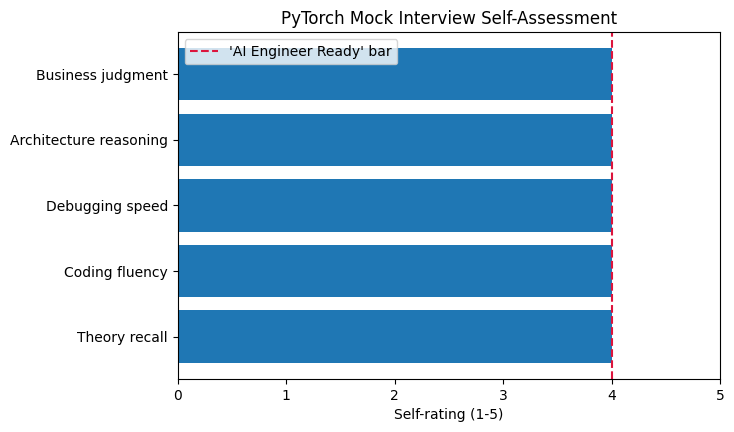

Average score: 4.0


In [ ]:
import matplotlib.pyplot as plt

categories_score = ["Theory recall", "Coding fluency", "Debugging speed", "Architecture reasoning", "Business judgment"]
my_scores = [4, 4, 4, 4, 4]   # <-- EDIT based on your honest self-assessment

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(categories_score, my_scores, color="tab:blue")
ax.set_xlim(0, 5)
ax.axvline(4, color="crimson", linestyle="--", label="'AI Engineer Ready' bar")
ax.set_xlabel("Self-rating (1-5)")
ax.set_title("PyTorch Mock Interview Self-Assessment")
ax.legend()
plt.show()
print(f"Average score: {sum(my_scores)/len(my_scores):.1f}")


---

# COURSE COMPLETE — FINAL CLASSIFICATION

| Level | Signal |
|---|---|
| **Beginner** | Comfortable with `model(x)`, still consulting docs for every new layer type |
| **PyTorch Learner** | Fluent with tensors, autograd, and basic `nn.Module` construction |
| **Intermediate** | Builds full training loops unaided, understands device management and train/eval mode |
| **Advanced** | Debugs unfamiliar errors independently, builds custom architectures (CNNs, RNNs, Transformers) from scratch |
| **Deep Learning Ready** | Comfortable across CV, NLP, and sequence modeling; understands the full training-to-deployment pipeline |
| **AI Engineer Ready** | Passes this notebook's mock interview comfortably, completed the capstone independently, reasons fluently about production deployment and scale |
| **Strong AI Engineer** | Additionally reasons well about LLM fine-tuning/PEFT, distributed training, and genuine research-paper implementation |
| **Senior-Level / PyTorch Specialist** | Additionally can review and improve others' PyTorch code confidently, reasons fluently about when PyTorch is (or isn't) the right tool, and can reason through novel AI system designs under real business constraints |

---

# END OF THE PYTORCH MASTERY COURSE

You have completed all 104 chapters across 17 notebooks:
1. Chapters 1–5 — Ecosystem, Installation, Tensor Mastery, Data Types, Creation
2. Chapters 6–10 — Indexing, Reshaping, Broadcasting, Math Operations, Matrix Operations
3. Chapters 11–15 — Concatenation/Stacking, Reproducibility, Autograd, Backpropagation, Gradient Management
4. Chapters 16–20 — nn.Module, Layers, Activations, Loss Functions, Optimizers
5. Chapters 21–25 — LR Schedulers, First Neural Network, Training Loop, Dataset/DataLoader, Custom Datasets
6. Chapters 26–31 — Collate Functions, GPU/CUDA, GPU Performance, Mixed Precision, Initialization, Regularization
7. Chapters 32–38 — Diagnostics, Debugging, Experiment Tracking, CNN Fundamentals, CNN From Scratch, CV Pipeline, Transfer Learning
8. Chapters 39–45 — Modern CNNs, Image Classification Project, Object Detection, Segmentation, Sequence Models, RNN, LSTM
9. Chapters 46–52 — GRU, NLP, Embeddings, Attention, Transformers, Transformer From Scratch, NLP Project
10. Chapters 53–58 — Hugging Face, LLMs, Mini Language Model, Text Generation, LLM Fine-Tuning, LoRA/PEFT
11. Chapters 59–64 — Quantization, ONNX, TorchScript, Model Serving, REST API, Docker
12. Chapters 65–71 — Monitoring, A/B Testing, Edge/Mobile Deployment, Distributed Training, Data Parallelism, Gradient Accumulation
13. Chapters 72–78 — Checkpointing, Custom Architectures, Custom Autograd, torch.compile, Profiling, Memory Optimization, Gradient Clipping
14. Chapters 79–85 — Large-Scale Training, Project Structure, Testing, **4 End-to-End Projects** (CV, NLP, LLM, Recommendation)
15. Chapters 86–92 — **Time-Series Project**, PyTorch vs Scikit-learn, Cross-Library Fluency, Model Selection, AI System Design
16. Chapters 93–98 — Full Interview Mastery, Coding/Debugging Interviews, Real-World Scenarios, Interview Traps, Performance Engineering
17. Chapters 99–104 — Research Paper Implementation, Model Reimplementation, Code Reading, Code Quality, **Master Capstone**, **Mock Interview**

Combined with your completed **Scikit-learn Mastery** course (97 chapters, 14 notebooks), you now have a continuous, connected foundation from classical ML through deep learning, transformers, and LLMs — genuinely equipped to design, implement, train, debug, optimize, deploy, and explain modern neural network systems, not merely call `.fit()` and `.predict()`.
